# Task 2: Damped Harmonic Oscillator

## Setup and Network Architecture

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

In [2]:
seed = 42

rng = np.random.default_rng(seed)
torch.manual_seed(seed)
torch.set_default_dtype(torch.float64) # Make torch datatype match numpy default

In [3]:
class Net(nn.Module):
    def __init__(self, input_size=1, output_size=1, hidden_layers=[32, 32], activation=nn.Tanh):
        """
        input_size: int, number of features in input
        output_size: int, number of output neurons
        hidden_layers: list of ints, each int is the number of neurons in that hidden layer
        activation: nn.Module, activation function class (default nn.Tanh)
        """
        super(Net, self).__init__()

        layers = []

        # Input layer -> first hidden layer
        layers.append(nn.Linear(input_size, hidden_layers[0]))
        layers.append(activation())

        # Hidden layers
        for i in range(1, len(hidden_layers)):
            layers.append(nn.Linear(hidden_layers[i-1], hidden_layers[i]))
            layers.append(activation())

        # Output layer
        layers.append(nn.Linear(hidden_layers[-1], output_size))

        # Combine layers into a Sequential module
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

## Physical System and Exact Solution

In [4]:
# Define system parameters
t0 = 0.0
T = 1.0

m = 1 # mass
k = 500 # spring constant
mu = 5.0 # friction constant

d = mu/(2*m)
w0 = np.sqrt(k/m)
w = np.sqrt(w0**2 - d**2)

# Define initial conditions
x_t0_true = torch.tensor([[1.0]])
v_t0_true = torch.tensor([[0.0]])

# Closed from solution
phi = np.arctan(-d/w)
A = 1/(2*np.cos(phi))

x_sol = lambda t : np.exp(-d*t)*(2*A*np.cos(phi + w*t))

## Task 2.1 — Generate Training Data

In [5]:
# Generate datapoints
t_data = rng.uniform(low=0.0, high=0.5, size=10)
x_data = x_sol(t_data)

## Task 2.2 — Data-Only Neural Network

In [6]:
net = Net(1,1,[32]) # Initialize network

# Define optimizer
optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)

# number of training passses
num_epochs = 20_000
# store loss
train_losses = []

# training loop
for e in range(num_epochs):
    # get training input and expected output as torch Variables and make sure type is correct
    tr_input = torch.from_numpy(t_data).reshape(-1, 1)
    tr_targets = torch.from_numpy(x_data).reshape(-1, 1)
    
    # Reset gradients from the previous iteration
    optimizer.zero_grad()
    # predict by running forward pass
    tr_output = net(tr_input)
    # Compute mean squared error (MSE)
    tr_loss = F.mse_loss(tr_output, tr_targets)
    # compute gradients given loss
    tr_loss.backward()
    # update the parameters given the computed gradients
    optimizer.step()
    
    # store training loss
    train_losses.append(tr_loss.detach().numpy())
    
    if e % (num_epochs//10) == 0:
        print(f"Epoch {e}, Train Cost: {train_losses[-1]:.3f}")

Epoch 0, Train Cost: 0.703
Epoch 2000, Train Cost: 0.016
Epoch 4000, Train Cost: 0.015
Epoch 6000, Train Cost: 0.015
Epoch 8000, Train Cost: 0.014
Epoch 10000, Train Cost: 0.010
Epoch 12000, Train Cost: 0.001
Epoch 14000, Train Cost: 0.000
Epoch 16000, Train Cost: 0.000
Epoch 18000, Train Cost: 0.000


### Evaluation and Extrapolation

C:\Users\oloms\AppData\Local\Temp\ipykernel_18160\3175266171.py:21: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  x_sol = lambda t : np.exp(-d*t)*(2*A*np.cos(phi + w*t))


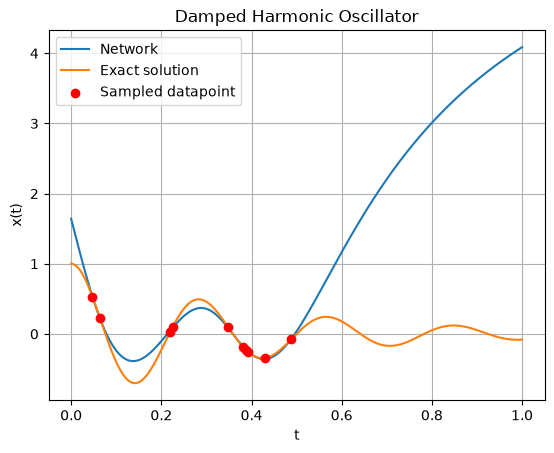

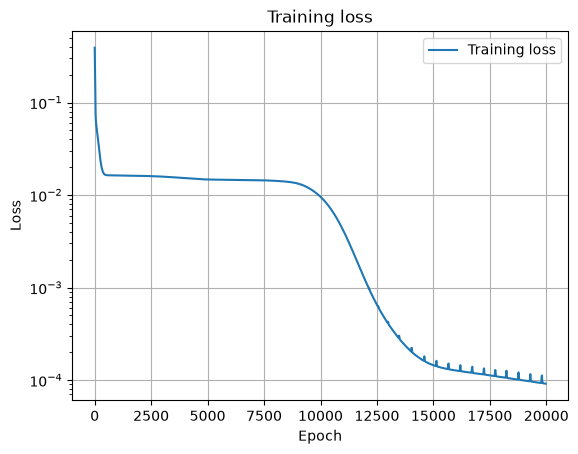

In [7]:
# Evaluation
net.eval()
t_test = torch.linspace(t0, 1.0, 10000).unsqueeze(1)

with torch.no_grad():
    x_pred = net(t_test)
plt.figure()
# Plot PINN approximation
plt.plot(t_test.numpy(), x_pred.numpy(), label="Network")

# Plot the exact analytical solution
plt.plot(t_test, x_sol(t_test), label="Exact solution")

# Datapoint
plt.scatter(t_data, x_data, color="red", label="Sampled datapoint", zorder=5)

plt.xlabel("t")
plt.ylabel("x(t)")
plt.grid()
plt.title("Damped Harmonic Oscillator")
plt.legend()
plt.show()

# Moving average
window = 30
train_losses = np.convolve(train_losses, np.ones(window)/window, mode='valid')

plt.figure()
plt.plot(train_losses, label = "Training loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.yscale("log")
plt.grid()
plt.title("Training loss")
plt.legend()
plt.show()


## Task 2.3 — Physics-Informed Loss and Analytical Gradients

In [8]:
# Collocation points

N = 1000
t_col = np.linspace(t0, T, N)

# Initialize network parameters
M = 32 # number of neurons in hidden layer

W1 = rng.normal(0, 0.1, size=(M, 1))
b1 =np.zeros((M, 1))

W2 = rng.normal(0, 0.1, size=(1, M))
b2 =np.zeros((1, 1))

params = (W1, b1, W2, b2)

# Network
def z(t, params): # Hidden layer
    W1, b1, W2, b2 = params
    return np.tanh(W1 * t + b1)

def f(t, params): # f(t) (Output layer)
    W1, b1, W2, b2 = params
    return W2 @ z(t, params) + b2

# Network derivatives
def D(t, params):
    return np.diag((1 - z(t, params)**2).flatten())

def Q(t, params): 
    z_t = z(t, params)
    return np.diag((-2 * z_t * (1 - z_t**2)).flatten())

def df_dt(t, params): # f'(t)
    W1, b1, W2, b2 = params
    return W2 @ D(t, params) @ W1

def d2f_dt2(t, params): # f''(t)
    W1, b1, W2, b2 = params
    return W2 @ Q(t, params) @ (W1 * W1)

# Physics residual
def r_phys(t, params):
    return (d2f_dt2(t, params) + (mu/m) * df_dt(t, params) + (k/m) * f(t, params))

### PINN Loss Function

In [9]:
lam_phys, lam_IC = 1e-3, 1.0 # Loss term weights

def L(params, lam_phys=lam_phys, lam_IC=lam_IC): # Loss function

    L_data = np.mean((f(np.ravel(t_data), params).ravel() - np.ravel(x_data))**2)

    L_phys = np.mean([r_phys(t, params).item()**2 for t in t_col])

    L_IC = ((f(0, params).item() - 1)**2 + df_dt(0, params).item()**2)

    Loss = L_data + lam_phys * L_phys + lam_IC * L_IC

    return Loss, L_data, L_phys, L_IC

### Analytical Weight Gradients

In [10]:
def dL_dW2(params, lam_phys=lam_phys, lam_IC=lam_IC):

    W1, b1, W2, b2 = params

    # Data loss gradient
    gradients = []

    for t, x in zip(np.ravel(t_data), np.ravel(x_data)): # Loops over all t_data and x_data pairs
        grad = (2 * (f(t, params).item() - x) * (z(t, params)).T)
        gradients.append(grad)

    dL_data_dW2 = np.mean(gradients, axis=0)

    # Physics loss gradient
    gradients = []

    for t in t_col: # Loops over all collocation points

        grad = (k/m) * (z(t, params)).T # (k/m)*df/dW2
        grad += (mu/m) * (D(t, params) @ W1).T # (mu/m)*df'/dW2
        grad += (Q(t, params) @ (W1 * W1)).T # df''/dW2
        grad *= 2 * r_phys(t, params).item()

        gradients.append(grad)

    dL_phys_dW2 = np.mean(gradients, axis=0)

    # Initial condition loss gradient
    dL_IC_dW2 = (2 * (f(0, params).item() - 1) * (z(0, params)).T) + (2 * df_dt(0, params).item() * (D(0, params) @ W1).T)

    # Total loss gradient
    dL_dW2 = (dL_data_dW2 + lam_phys * dL_phys_dW2 + lam_IC * dL_IC_dW2)

    return dL_dW2

In [11]:
def S(t, params):
    z_t = z(t, params)
    return np.diag(((6*z_t**2 - 2) * (1 - z_t**2)).flatten())

def dL_dW1(params, lam_phys=lam_phys, lam_IC=lam_IC):

    W1, b1, W2, b2 = params

    A = np.diag(W1.flatten())
    B = np.diag((W1 * W1).flatten())

    # Data loss gradient
    gradients = []

    for t, x in zip(np.ravel(t_data), np.ravel(x_data)): # Loops over all t_data and x_data pairs
        grad = (2 * (f(t, params).item() - x) * t * (W2 @ D(t, params)).T)
        gradients.append(grad)

    dL_data_dW1 = np.mean(gradients, axis=0)

    # Physics loss gradient
    gradients = []

    for t in t_col: # Loops over all collocation points

        grad = (k/m) * t * (W2 @ D(t, params)).T # (k/m)*df/dW1
        grad += (mu/m) * (W2 @ (D(t, params) + t * Q(t, params) @ A)).T # (mu/m)*df'/dW1
        grad += (W2 @ (2 * Q(t, params) @ A + t * S(t, params) @ B)).T # df''/dW1
        grad *= 2 * r_phys(t, params).item()

        gradients.append(grad)

    dL_phys_dW1 = np.mean(gradients, axis=0)

    # Initial condition loss gradient
    dL_IC_dW1 = (2 * df_dt(0, params).item() * (W2 @ D(0, params)).T)

    # Total loss gradient
    dL_dW1 = (dL_data_dW1 + lam_phys * dL_phys_dW1 + lam_IC * dL_IC_dW1)

    return dL_dW1

## Task 2.4 — Finite-Difference Gradient Verification

In [12]:
# Compare analytical gradient with finite difference approximation

def fin_diff(L, params, param_idx=0, index=(0, 0), eps=1e-5):

    params_plus = list(params)
    params_minus = list(params)

    # Copy the parameter matrix being differentiated
    params_plus[param_idx] = params[param_idx].copy()
    params_minus[param_idx] = params[param_idx].copy()

    # Perturb selected weight
    params_plus[param_idx][index] += eps
    params_minus[param_idx][index] -= eps

    L_plus,_,_,_ = L(tuple(params_plus))
    L_minus,_,_,_ = L(tuple(params_minus))

    # Finite difference
    grad_numerical = (L_plus - L_minus) / (2 * eps)

    return grad_numerical

# M number of neurons in hidden layer
grad_numerical, grad_analytical = np.zeros(M), np.zeros(M)

# Calculate the partial derivatives for each index
for i in range(M):
    grad_numerical[i] = fin_diff(L, params, 0, (i,0))
    grad_analytical[i] = dL_dW1(params)[(i,0)]

print(f"Maximum absolute difference W1: {np.max(np.abs(grad_analytical - grad_numerical)):.3e}")

Maximum absolute difference W1: 2.569e-11


## Task 2.5 — Training with Analytical Gradients

In [13]:
def dL_db2(params, lam_phys=lam_phys, lam_IC=lam_IC):

    W1, b1, W2, b2 = params

    # Data loss gradient
    gradients = []

    for t, x in zip(np.ravel(t_data), np.ravel(x_data)): # Loops over all t_data and x_data pairs
        grad = (2 * (f(t, params).item() - x))
        gradients.append(grad)

    dL_data_db2 = np.mean(gradients, axis=0)

    # Physics loss gradient
    gradients = []

    for t in t_col: # Loops over all collocation points

        grad = (k/m) # (k/m)*df/db2
        grad *= 2 * r_phys(t, params).item()

        gradients.append(grad)

    dL_phys_db2 = np.mean(gradients, axis=0)

    # Initial condition loss gradient
    dL_IC_db2 = (2 * (f(0, params).item() - 1))

    # Total loss gradient
    dL_db2 = (dL_data_db2 + lam_phys * dL_phys_db2 + lam_IC * dL_IC_db2)

    return np.array([[dL_db2]])

In [14]:
def dL_db1(params, lam_phys=lam_phys, lam_IC=lam_IC):

    W1, b1, W2, b2 = params

    A = np.diag(W1.flatten())
    B = np.diag((W1 * W1).flatten())

    # Data loss gradient
    gradients = []

    for t, x in zip(np.ravel(t_data), np.ravel(x_data)): # Loops over all t_data and x_data pairs
        grad = (2 * (f(t, params).item() - x) * (W2 @ D(t, params)).T)
        gradients.append(grad)

    dL_data_db1 = np.mean(gradients, axis=0)

    # Physics loss gradient
    gradients = []

    for t in t_col: # Loops over all collocation points

        grad = (k/m)  * (W2 @ D(t, params)).T # (k/m)*df/db1
        grad += (mu/m) * (W2 @ Q(t, params) @ A).T # (mu/m)*df'/db1
        grad += (W2 @ S(t, params) @ B).T # df''/db1
        grad *= 2 * r_phys(t, params).item()

        gradients.append(grad)

    dL_phys_db1 = np.mean(gradients, axis=0)

    # Initial condition loss gradient
    dL_IC_db1 = ((2 * (f(0, params).item() - 1) * (W2 @ D(0, params))).T 
                + (2 * df_dt(0, params).item() * (W2 @ Q(0,params) @ A)).T
    )

    # Total loss gradient
    dL_db1 = (dL_data_db1 + lam_phys * dL_phys_db1 + lam_IC * dL_IC_db1)

    return dL_db1

### Training Configuration

In [ ]:
from scipy.optimize import minimize # TODO make new optimizer using L-BFGS-B

# result = minimize(
#     fun=loss_flat,
#     x0=initial_params_flat,
#     jac=gradient_flat,
#     method="L-BFGS-B",
#     options={"maxiter": 1000}
# )

grad_L = (dL_dW1, dL_db1, dL_dW2, dL_db2)

def update_parameters(params, learning_rate=0.01, lam_phys=lam_phys, lam_IC=lam_IC):

  # Calculate all gradients before updating
  gradients = [grad(params, lam_phys=lam_phys, lam_IC=lam_IC) for grad in grad_L]

  updated_params = []
  for p, grad in zip(params, gradients):
    p_new = p - learning_rate * grad
    updated_params.append(p_new)
  return tuple(updated_params)

In [16]:
# Xavier initilization
def init_weights():
    rng = np.random.default_rng(seed)
    M = 32

    limit = np.sqrt(6 / (1 + M))

    W1 = rng.uniform(-limit, limit, size=(M, 1))
    b1 = np.zeros((M, 1))

    W2 = rng.uniform(-limit, limit, size=(1, M))
    b2 = np.zeros((1, 1))

    params = (W1, b1, W2, b2)
    return params

# Network
def z(t, params): # Hidden layer
    W1, b1, W2, b2 = params
    return np.tanh(W1 * t + b1)

def f(t, params): # f(t) (Output layer)
    W1, b1, W2, b2 = params
    return W2 @ z(t, params) + b2

In [17]:
from time import perf_counter

params = init_weights()

# Initialize training hyperparameters
EPOCHS = 1000 # TODO insert number of epochs
LEARN_R = 1e-3

# Loss term weights
lam_IC = 10.0
lam_phys = 1e-4

train_losses = []

start = perf_counter()
for e in range(EPOCHS):
     
    # Forward pass and loss computation
    loss, data_loss, physic_loss, ic_loss = L(params, lam_phys=lam_phys, lam_IC=lam_IC)
    
    # gradient descent update
    params = update_parameters(params, LEARN_R, lam_phys=lam_phys, lam_IC=lam_IC)
    
    # Training loss
    train_losses.append(loss)
    
    if e % (EPOCHS//10) == 0:
            print(f"Epoch {e}, Train Cost: {train_losses[-1]:.3f}, Loss terms: Data: {data_loss:.3f}, Physics: {physic_loss:.3f}, IC: {ic_loss:.3f} "
                   ,f"Total run time: {perf_counter()-start:.1f} sec.")
trained_params = params

Epoch 0, Train Cost: 13.641, Loss terms: Data: 0.114, Physics: 15733.609, IC: 1.195  Total run time: 0.4 sec.
Epoch 100, Train Cost: 6.305, Loss terms: Data: 0.143, Physics: 15865.597, IC: 0.458  Total run time: 31.0 sec.
Epoch 200, Train Cost: 6.299, Loss terms: Data: 0.143, Physics: 15878.807, IC: 0.457  Total run time: 60.0 sec.
Epoch 300, Train Cost: 6.292, Loss terms: Data: 0.143, Physics: 15884.556, IC: 0.456  Total run time: 89.7 sec.
Epoch 400, Train Cost: 6.284, Loss terms: Data: 0.143, Physics: 15891.144, IC: 0.455  Total run time: 123.3 sec.
Epoch 500, Train Cost: 6.276, Loss terms: Data: 0.144, Physics: 15898.649, IC: 0.454  Total run time: 162.9 sec.
Epoch 600, Train Cost: 6.268, Loss terms: Data: 0.144, Physics: 15907.172, IC: 0.453  Total run time: 193.9 sec.
Epoch 700, Train Cost: 6.259, Loss terms: Data: 0.144, Physics: 15916.837, IC: 0.452  Total run time: 225.3 sec.
Epoch 800, Train Cost: 6.250, Loss terms: Data: 0.144, Physics: 15927.801, IC: 0.451  Total run time: 

### Results and Loss Curves

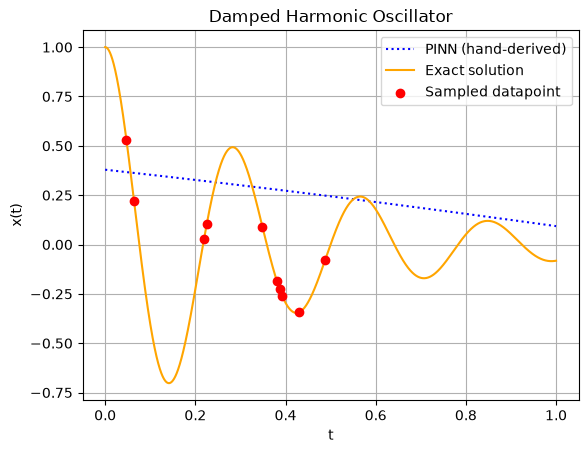

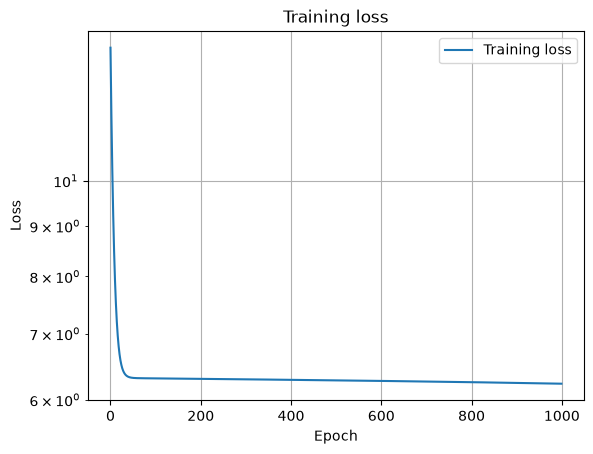

In [18]:
# Evaluation
t_test = np.linspace(t0, T, 10000)
x_pred = f(t_test,trained_params).flatten()

plt.figure()
# Plot PINN approximation
plt.plot(t_test, x_pred, label="PINN (hand-derived)", linestyle=":", color="blue")

# Plot analytical solution
plt.plot(t_test, x_sol(t_test), label="Exact solution", color="orange")

# Datapoint
plt.scatter(t_data, x_data, color="red", label="Sampled datapoint", zorder=5)

plt.xlabel("t")
plt.ylabel("x(t)")
plt.grid()
plt.title("Damped Harmonic Oscillator")
plt.legend()
plt.show()


# Moving average
window = 30
numpy_losses = np.convolve(train_losses, np.ones(window)/window, mode='valid')

plt.figure()
plt.plot(train_losses, label = "Training loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.yscale("log")
plt.grid()
plt.title("Training loss")
plt.legend()
plt.show()

## Task 2.6 — Comparison with PyTorch Autograd

In [19]:
# Define initial conditions
x_t0_true = torch.tensor([[1.0]])
v_t0_true = torch.tensor([[0.0]])

# Initial conditions (convert to float)
x0_true = x_t0_true.squeeze().item()
v0_true = v_t0_true.squeeze().item()
y0 = [x0_true, v0_true]  # x(0), v(0)

In [20]:
params = init_weights()
W1, b1, W2, b2 = params

pinn = Net(1,1,[32]) # Initialize PINN

with torch.no_grad():
    pinn.model[0].weight.copy_(torch.from_numpy(W1))
    pinn.model[0].bias.copy_(torch.from_numpy(b1.flatten()))

    pinn.model[2].weight.copy_(torch.from_numpy(W2))
    pinn.model[2].bias.copy_(torch.from_numpy(b2.flatten()))

# Define optimizer
# optimizer = torch.optim.Adam(pinn.parameters(), lr=1e-3)
optimizer = torch.optim.SGD(pinn.parameters(), lr=1e-3)

# Loss term weights
lam_IC = 10.0
lam_phys = 1e-4

t_data_tensor = torch.from_numpy(t_data).reshape(-1, 1)
x_data_tensor = torch.from_numpy(x_data).reshape(-1, 1)

t = torch.from_numpy(t_col).reshape(-1, 1)
t.requires_grad_(True)

# Reset gradients from the previous iteration
optimizer.zero_grad()

x = pinn(t)

# Compute velocity and acceleration
v = torch.autograd.grad(
    x, t,
    grad_outputs=torch.ones_like(x),
    create_graph=True
)[0]

a = torch.autograd.grad(
    v, t,
    grad_outputs=torch.ones_like(v),
    create_graph=True
)[0]

# physics loss
residual = a + (mu/m) * v + (k/m) * x 
physic_loss = torch.mean(residual**2)

# IC loss
t0_tensor = torch.tensor([[t0]], requires_grad=True)
x_t0 = pinn(t0_tensor)
v_t0 = torch.autograd.grad(
    x_t0, t0_tensor,
    grad_outputs=torch.ones_like(x_t0),
    create_graph=True
)[0]

ic_loss = torch.mean((x_t0 - x_t0_true)**2 + (v_t0 - v_t0_true)**2)

# Datapoint loss
x_data_pred = pinn(t_data_tensor)

data_loss = torch.mean((x_data_pred - x_data_tensor)**2)

# Total loss
tr_loss = data_loss + lam_phys * physic_loss + lam_IC * ic_loss

# compute gradients given loss
tr_loss.backward()

### Gradient Comparison at Initialization

In [21]:

# Analytical gradients
grad_W1_analytical = dL_dW1(params, lam_phys, lam_IC)
grad_W2_analytical = dL_dW2(params, lam_phys, lam_IC)

# Autograd gradients
grad_W1_torch = pinn.model[0].weight.grad.detach().numpy()
grad_W2_torch = pinn.model[2].weight.grad.detach().numpy()

# Relative L2-errors
rel_W1 = np.linalg.norm(grad_W1_analytical - grad_W1_torch) / np.linalg.norm(grad_W1_torch)

rel_W2 = np.linalg.norm(grad_W2_analytical - grad_W2_torch) / np.linalg.norm(grad_W2_torch)

print(f"Relative L2-error W1 (%): {rel_W1*100:.3e}%")
print(f"Relative L2-error W2 (%): {rel_W2*100:.3e}%")

Relative L2-error W1 (%): 2.651e-14%
Relative L2-error W2 (%): 2.786e-14%


### Training with Autograd

In [22]:
pinn = Net(1,1,[32]) # Initialize PINN

with torch.no_grad():
    pinn.model[0].weight.copy_(torch.from_numpy(W1))
    pinn.model[0].bias.copy_(torch.from_numpy(b1.flatten()))

    pinn.model[2].weight.copy_(torch.from_numpy(W2))
    pinn.model[2].bias.copy_(torch.from_numpy(b2.flatten()))

# Define optimizer
# optimizer = torch.optim.Adam(pinn.parameters(), lr=1e-3)
optimizer = torch.optim.SGD(pinn.parameters(), lr=1e-3)

# Loss term weights
lam_IC = 10.0
lam_phys = 1e-4

# number of training passses
EPOCHS = 1000
# store loss
train_losses = []

t_data_tensor = torch.from_numpy(t_data).reshape(-1, 1)
x_data_tensor = torch.from_numpy(x_data).reshape(-1, 1)

t = torch.from_numpy(t_col).reshape(-1, 1)
t.requires_grad_(True)

# training loop
for e in range(EPOCHS):
    
    # Reset gradients from the previous iteration
    optimizer.zero_grad()

    x = pinn(t)

    # Compute velocity and acceleration
    v = torch.autograd.grad(
        x, t,
        grad_outputs=torch.ones_like(x),
        create_graph=True
    )[0]

    a = torch.autograd.grad(
        v, t,
        grad_outputs=torch.ones_like(v),
        create_graph=True
    )[0]

    # physics loss
    residual = a + (mu/m) * v + (k/m) * x 
    physic_loss = torch.mean(residual**2)

    # IC loss
    t0_tensor = torch.tensor([[t0]], requires_grad=True)
    x_t0 = pinn(t0_tensor)
    v_t0 = torch.autograd.grad(
        x_t0, t0_tensor,
        grad_outputs=torch.ones_like(x_t0),
        create_graph=True
    )[0]

    ic_loss = torch.mean((x_t0 - x_t0_true)**2 + (v_t0 - v_t0_true)**2)

    # Datapoint loss
    x_data_pred = pinn(t_data_tensor)

    data_loss = torch.mean((x_data_pred - x_data_tensor)**2)

    # Total loss
    tr_loss = data_loss + lam_phys * physic_loss + lam_IC * ic_loss

    # compute gradients given loss
    tr_loss.backward()

    # update the parameters given the computed gradients
    optimizer.step()
    
    # store training loss
    train_losses.append(tr_loss.detach().numpy())
    
    if e % (EPOCHS//10) == 0:
        print(f"Epoch {e}, Train Cost: {train_losses[-1]:.3f}, Loss terms: Data: {data_loss:.3f}, Physics: {physic_loss:.3f}, IC: {ic_loss:.3f} "
               )

Epoch 0, Train Cost: 13.641, Loss terms: Data: 0.114, Physics: 15733.609, IC: 1.195 
Epoch 100, Train Cost: 6.305, Loss terms: Data: 0.143, Physics: 15865.597, IC: 0.458 
Epoch 200, Train Cost: 6.299, Loss terms: Data: 0.143, Physics: 15878.807, IC: 0.457 
Epoch 300, Train Cost: 6.292, Loss terms: Data: 0.143, Physics: 15884.556, IC: 0.456 
Epoch 400, Train Cost: 6.284, Loss terms: Data: 0.143, Physics: 15891.144, IC: 0.455 
Epoch 500, Train Cost: 6.276, Loss terms: Data: 0.144, Physics: 15898.649, IC: 0.454 
Epoch 600, Train Cost: 6.268, Loss terms: Data: 0.144, Physics: 15907.172, IC: 0.453 
Epoch 700, Train Cost: 6.259, Loss terms: Data: 0.144, Physics: 15916.837, IC: 0.452 
Epoch 800, Train Cost: 6.250, Loss terms: Data: 0.144, Physics: 15927.801, IC: 0.451 
Epoch 900, Train Cost: 6.239, Loss terms: Data: 0.145, Physics: 15940.260, IC: 0.450 


### Comparison of Predictions and Loss Curves

C:\Users\oloms\AppData\Local\Temp\ipykernel_18160\3175266171.py:21: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  x_sol = lambda t : np.exp(-d*t)*(2*A*np.cos(phi + w*t))


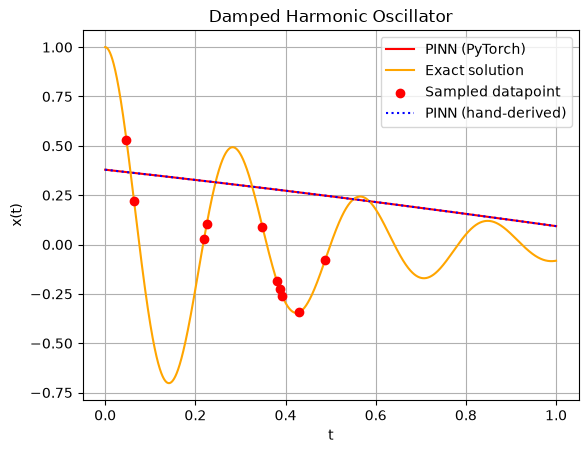

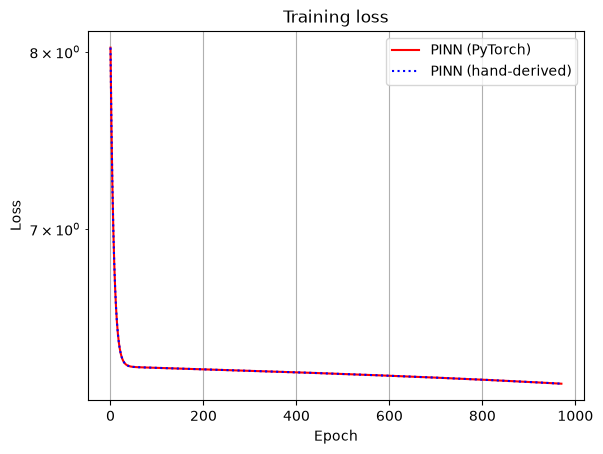

In [23]:
# Evaluate trained model on the full time interval
pinn.eval()
t_test = torch.linspace(t0, T, 10000).unsqueeze(1)

with torch.no_grad():
    x_pred = pinn(t_test)
plt.figure()
# Plot PINN approximation
plt.plot(t_test.numpy(), x_pred.numpy(), label="PINN (PyTorch)", color="red")

# Plot the exact analytical solution
plt.plot(t_test, x_sol(t_test), label="Exact solution", color="orange")

# Datapoint
plt.scatter(t_data, x_data, color="red", label="Sampled datapoint", zorder=5)

# Evaluation Numpy
t_test = np.linspace(t0, T, 10000)
x_pred = f(t_test, trained_params).flatten()

# Plot PINN approximation
plt.plot(t_test, x_pred, label="PINN (hand-derived)", linestyle=':', color="blue")

plt.xlabel("t")
plt.ylabel("x(t)")
plt.grid()
plt.title("Damped Harmonic Oscillator")
plt.legend()
plt.show()

# Moving average
window = 30
torch_losses = np.convolve(train_losses, np.ones(window)/window, mode='valid')

plt.figure()
plt.plot(torch_losses, label="PINN (PyTorch)", color="red")
plt.plot(numpy_losses, label="PINN (hand-derived)", linestyle=':', color="blue")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.yscale("log")
plt.grid()
plt.title("Training loss")
plt.legend()
plt.show()

## Task 2.7 — Soft and Hard Enforcement of Initial Conditions

### Soft Enforcement

In [24]:
pinn = Net(1,1,[32]) # Initialize PINN

with torch.no_grad():
    pinn.model[0].weight.copy_(torch.from_numpy(W1))
    pinn.model[0].bias.copy_(torch.from_numpy(b1.flatten()))

    pinn.model[2].weight.copy_(torch.from_numpy(W2))
    pinn.model[2].bias.copy_(torch.from_numpy(b2.flatten()))

# Define optimizer
optimizer = torch.optim.Adam(pinn.parameters(), lr=1e-3)
# optimizer = torch.optim.SGD(pinn.parameters(), lr=1e-3)

# Loss term weights
lam_IC = 10.0
lam_phys = 1e-4

# number of training passses
EPOCHS = 20_000
# store loss
train_losses = []

t_data_tensor = torch.from_numpy(t_data).reshape(-1, 1)
x_data_tensor = torch.from_numpy(x_data).reshape(-1, 1)

t = torch.from_numpy(t_col).reshape(-1, 1)
t.requires_grad_(True)

# training loop
for e in range(EPOCHS):
    
    # Reset gradients from the previous iteration
    optimizer.zero_grad()

    x = pinn(t)

    # Compute velocity and acceleration
    v = torch.autograd.grad(
        x, t,
        grad_outputs=torch.ones_like(x),
        create_graph=True
    )[0]

    a = torch.autograd.grad(
        v, t,
        grad_outputs=torch.ones_like(v),
        create_graph=True
    )[0]

    # physics loss
    residual = a + (mu/m) * v + (k/m) * x 
    physic_loss = torch.mean(residual**2)

    # IC loss
    t0_tensor = torch.tensor([[t0]], requires_grad=True)
    x_t0 = pinn(t0_tensor)
    v_t0 = torch.autograd.grad(
        x_t0, t0_tensor,
        grad_outputs=torch.ones_like(x_t0),
        create_graph=True
    )[0]

    ic_loss = torch.mean((x_t0 - x_t0_true)**2 + (v_t0 - v_t0_true)**2)

    # Datapoint loss
    x_data_pred = pinn(t_data_tensor)

    data_loss = torch.mean((x_data_pred - x_data_tensor)**2)

    # Total loss
    tr_loss = data_loss + lam_phys * physic_loss + lam_IC * ic_loss

    # compute gradients given loss
    tr_loss.backward()

    # update the parameters given the computed gradients
    optimizer.step()
    
    # store training loss
    train_losses.append(tr_loss.detach().numpy())
    
    if e % (EPOCHS//10) == 0:
        print(f"Epoch {e}, Train Cost: {train_losses[-1]:.3f}, Loss terms: Data: {data_loss:.3f}, Physics: {physic_loss:.3f}, IC: {ic_loss:.3f} "
               )

# Moving average
window = 30
torch_losses = np.convolve(train_losses, np.ones(window)/window, mode='valid')

Epoch 0, Train Cost: 13.641, Loss terms: Data: 0.114, Physics: 15733.609, IC: 1.195 
Epoch 2000, Train Cost: 3.545, Loss terms: Data: 0.098, Physics: 18442.073, IC: 0.160 
Epoch 4000, Train Cost: 1.919, Loss terms: Data: 0.039, Physics: 13609.032, IC: 0.052 
Epoch 6000, Train Cost: 1.112, Loss terms: Data: 0.067, Physics: 8635.148, IC: 0.018 
Epoch 8000, Train Cost: 0.663, Loss terms: Data: 0.079, Physics: 5052.950, IC: 0.008 
Epoch 10000, Train Cost: 0.369, Loss terms: Data: 0.067, Physics: 2690.054, IC: 0.003 
Epoch 12000, Train Cost: 0.210, Loss terms: Data: 0.047, Physics: 1508.040, IC: 0.001 
Epoch 14000, Train Cost: 0.138, Loss terms: Data: 0.031, Physics: 1025.252, IC: 0.000 
Epoch 16000, Train Cost: 0.101, Loss terms: Data: 0.020, Physics: 784.040, IC: 0.000 
Epoch 18000, Train Cost: 0.076, Loss terms: Data: 0.013, Physics: 613.599, IC: 0.000 


### Hard Enforcement

In [25]:
pinn2 = Net(1,1,[32]) # Initialize PINN

with torch.no_grad():
    pinn2.model[0].weight.copy_(torch.from_numpy(W1))
    pinn2.model[0].bias.copy_(torch.from_numpy(b1.flatten()))

    pinn2.model[2].weight.copy_(torch.from_numpy(W2))
    pinn2.model[2].bias.copy_(torch.from_numpy(b2.flatten()))

# Define optimizer
optimizer = torch.optim.Adam(pinn2.parameters(), lr=1e-3)
# optimizer = torch.optim.SGD(pinn2.parameters(), lr=1e-3)

# Loss term weights
lam_IC = 10.0
lam_phys = 1e-4

# number of training passses
EPOCHS = 20_000
# store loss
train_losses = []

t_data_tensor = torch.from_numpy(t_data).reshape(-1, 1)
x_data_tensor = torch.from_numpy(x_data).reshape(-1, 1)

t = torch.from_numpy(t_col).reshape(-1, 1)
t.requires_grad_(True)

# training loop
for e in range(EPOCHS):
    
    # Reset gradients from the previous iteration
    optimizer.zero_grad()

    x = 1 + t**2 * pinn2(t)

    # Compute velocity and acceleration
    v = torch.autograd.grad(
        x, t,
        grad_outputs=torch.ones_like(x),
        create_graph=True
    )[0]

    a = torch.autograd.grad(
        v, t,
        grad_outputs=torch.ones_like(v),
        create_graph=True
    )[0]

    # physics loss
    residual = a + (mu/m) * v + (k/m) * x 
    physic_loss = torch.mean(residual**2)

    # IC loss
    t0_tensor = torch.tensor([[t0]], requires_grad=True)
    x_t0 = 1 + t0_tensor**2 * pinn2(t0_tensor)
    v_t0 = torch.autograd.grad(
        x_t0, t0_tensor,
        grad_outputs=torch.ones_like(x_t0),
        create_graph=True
    )[0]

    ic_loss = torch.mean((x_t0 - x_t0_true)**2 + (v_t0 - v_t0_true)**2)

    # Datapoint loss
    x_data_pred = 1 + t_data_tensor**2 * pinn2(t_data_tensor)

    data_loss = torch.mean((x_data_pred - x_data_tensor)**2)

    # Total loss
    tr_loss = data_loss + lam_phys * physic_loss

    # compute gradients given loss
    tr_loss.backward()

    # update the parameters given the computed gradients
    optimizer.step()
    
    # store training loss
    train_losses.append(tr_loss.detach().numpy())
    
    if e % (EPOCHS//10) == 0:
        print(f"Epoch {e}, Train Cost: {train_losses[-1]:.3f}, Loss terms: Data: {data_loss:.3f}, Physics: {physic_loss:.3f}, IC: {ic_loss:.3f} ")

Epoch 0, Train Cost: 32.517, Loss terms: Data: 1.131, Physics: 313852.305, IC: 0.000 
Epoch 2000, Train Cost: 5.951, Loss terms: Data: 0.260, Physics: 56910.982, IC: 0.000 
Epoch 4000, Train Cost: 3.432, Loss terms: Data: 0.108, Physics: 33238.114, IC: 0.000 
Epoch 6000, Train Cost: 2.309, Loss terms: Data: 0.075, Physics: 22337.782, IC: 0.000 
Epoch 8000, Train Cost: 1.692, Loss terms: Data: 0.081, Physics: 16106.033, IC: 0.000 
Epoch 10000, Train Cost: 1.269, Loss terms: Data: 0.094, Physics: 11753.077, IC: 0.000 
Epoch 12000, Train Cost: 0.933, Loss terms: Data: 0.097, Physics: 8365.346, IC: 0.000 
Epoch 14000, Train Cost: 0.679, Loss terms: Data: 0.089, Physics: 5898.914, IC: 0.000 
Epoch 16000, Train Cost: 0.500, Loss terms: Data: 0.074, Physics: 4264.236, IC: 0.000 
Epoch 18000, Train Cost: 0.389, Loss terms: Data: 0.058, Physics: 3307.547, IC: 0.000 


### Comparison of Results

### Network Output and Time Derivatives

C:\Users\oloms\AppData\Local\Temp\ipykernel_18160\3175266171.py:21: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  x_sol = lambda t : np.exp(-d*t)*(2*A*np.cos(phi + w*t))


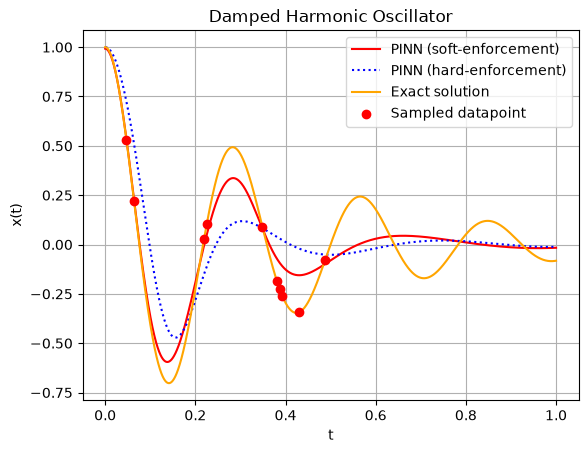

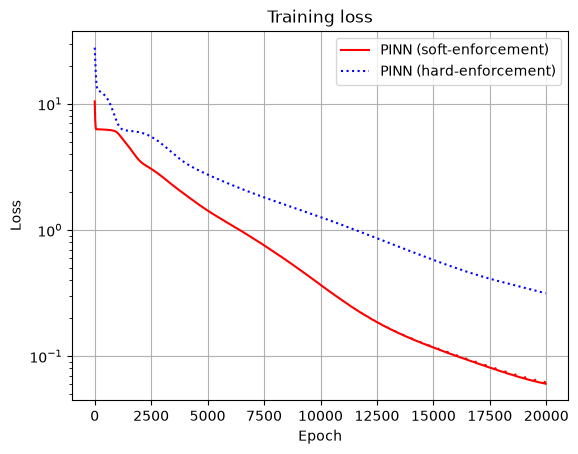

In [26]:
# Evaluate trained model on the full time interval
pinn2.eval()
t_test = torch.linspace(t0, T, 10000).unsqueeze(1)

# Evaluation
pinn.eval()

with torch.no_grad():
    x_pred = pinn(t_test)

plt.figure()
# Plot PINN approximation
plt.plot(t_test, x_pred, label="PINN (soft-enforcement)", color="red")

with torch.no_grad():
    x_pred = 1 + t_test**2 * pinn2(t_test)

# Plot PINN approximation
plt.plot(t_test.numpy(), x_pred.numpy(), label="PINN (hard-enforcement)", linestyle=':', color="blue")

# Plot the exact analytical solution
plt.plot(t_test, x_sol(t_test), label="Exact solution", color="orange")

# Datapoint
plt.scatter(t_data, x_data, color="red", label="Sampled datapoint", zorder=5)

plt.xlabel("t")
plt.ylabel("x(t)")
plt.grid()
plt.title("Damped Harmonic Oscillator")
plt.legend()
plt.show()

# Moving average
window = 30
torch2_losses = np.convolve(train_losses, np.ones(window)/window, mode='valid')

plt.figure()
plt.plot(torch_losses, label="PINN (soft-enforcement)", color="red")
plt.plot(torch2_losses, label="PINN (hard-enforcement)", linestyle=':', color="blue")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.yscale("log")
plt.grid()
plt.title("Training loss")
plt.legend()
plt.show()